# MC833 – Projeto 3 · Notebook 00: Pré-processamento dos traces MAWI

**O que ele faz:** lê os dois traces brutos da MAWI (samplepoint-F) e produz, para cada um, um conjunto de arquivos Parquet compactos de **no máximo ~195 MB por trace**:

| Arquivo | Conteúdo | Base |
|---|---|---|
| `<id>_serie_10ms.parquet` | Série temporal em bins de 10 ms: bytes e pacotes, totais e por TCP/UDP/ICMP/outro e por IPv4/IPv6 | todos os pacotes |
| `<id>_serie_1s.parquet` | Série por segundo + IPs de origem/destino únicos, fluxos únicos, SYNs | todos os pacotes |
| `<id>_fluxos.parquet` | Fluxos (5-tupla unidirecional), os maiores 1 milhão em bytes | todos os pacotes |
| `<id>_hist_fluxos.parquet` | Histograma (bins log) de pacotes e bytes por fluxo, com **todos** os fluxos | todos os pacotes |
| `<id>_portas.parquet` | Bytes/pacotes por porta de serviço (TCP/UDP) | todos os pacotes |
| `<id>_hist_tamanhos.parquet` | Histograma exato do tamanho dos pacotes por protocolo e versão IP | todos os pacotes |
| `<id>_pacotes_amostra.parquet` | Amostra aleatória uniforme de pacotes (usa o espaço que sobrar no orçamento) | amostra |
| `<id>_recorte.pcap` | Primeiros ~10 s do pcap **bruto** (para o exercício opcional de parsing) | recorte |
| `<id>_resumo.json` | Metadados e totais (duração, throughput média, nº de pacotes/fluxos etc.) | todos os pacotes |

### Requisitos
* Python ≥ 3.9 com `numpy`, `pandas`, `pyarrow` (o `numba` e o `psutil` são opcionais, mas recomendados). No Colab já vem tudo instalado.
* **RAM:** ~3–4 GB de pico (confira a linha de progresso). O Colab gratuito (12 GB) dá conta.
* **Disco local:** o pcap copiado (~10 GB descompactado, ~4 GB em `.gz`) + até ~10 GB de arquivos temporários da tabela de fluxos, apagados no final. O Colab oferece ~70+ GB.

> ### Sobre os dados brutos (leia antes de executar)
>
> Este notebook é **opcional** e serve como **referência** de como os dados da pasta `dados/` foram gerados. **Você não precisa executá-lo para fazer o Projeto 3**: os arquivos já processados (`dados/200702101400/` e `dados/202402101400/`) são os únicos necessários para os notebooks `01_EDA.ipynb` e `02_LSTM.ipynb`.
>
> Para evitar um download desnecessário de ~4 GB, **as pastas com *os* dados brutos (arquivos `.pcap`/`.dump`) não estão incluídas** na pasta do projeto. Os traces originais do MAWI (samplepoint-F, sábado, 10/02, 14:00 JST) podem ser obtidos aqui:
>
> - **Dados originais:** [LINK DOS DADOS ORIGINAIS]
> - 2007: https://mawi.wide.ad.jp/mawi/samplepoint-F/2007/200702101400.html `200702101400.dump.gz` (~364 MB)
> - 2024: https://mawi.wide.ad.jp/mawi/samplepoint-F/2024/202402101400.html `202402101400.pcap.gz` (~3,7 GB)
>
> Caso queira reproduzir o pré-processamento, baixe os arquivos, coloque-os no Drive e ajuste os caminhos `TRACES` e `PASTA_SAIDA` na seção de configuração (os caminhos padrão, `.../MC833_T3_2026/brutos/...`, não existem na pasta distribuída). Use o Colab com ~12 GB de RAM; a execução leva cerca de 10 a 15 minutos.

## 0. Ambiente

In [ ]:
# No Colab/Jupyter: instala o que faltar (silencioso). Em ambiente local, pode usar pip/conda normalmente.
import importlib, subprocess, sys
for pacote in ['pyarrow', 'numba', 'psutil']:
    if importlib.util.find_spec(pacote) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pacote])

EM_COLAB = 'google.colab' in sys.modules
if EM_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
print('Colab:', EM_COLAB)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab: True


## 1. Configuração
Ajuste os caminhos abaixo. Os arquivos podem ser `.pcap`, `.dump` (é o mesmo formato pcap clássico, só muda a extensão) ou estar compactados em `.gz`.

> **Dicas (Colab):** (1) ler direto do Google Drive é lento; com `COPIAR_PARA_LOCAL = True` o notebook copia o pcap para o disco local da VM (`/content`) antes de processar. (2) **Prefira subir os arquivos em `.gz`** (como vêm da MAWI: ~0,4 GB e ~3,7 GB). O Safari/macOS descompacta sozinho ao baixar, e aí os arquivos viram ~1 GB e ~10 GB. O notebook lê `.gz` direto, sem descompactar.

In [ ]:
import os

# Caminho de cada trace (id MAWI -> arquivo)
TRACES = {
    '200702101400': '/content/drive/MyDrive/MC833A_T3_2026/brutos/200702101400.dump.gz',
    '202402101400': '/content/drive/MyDrive/MC833A_T3_2026/brutos/202402101400.pcap.gz',
}
PASTA_SAIDA = '/content/drive/MyDrive/MC833A_T3_2026/dados'   # uma subpasta por trace será criada

PASTA_TEMP        = '/content'   # onde ficam os arquivos temporários da tabela de fluxos (disco local, apagados no final)
COPIAR_PARA_LOCAL = True     # copia o pcap do Drive para /content antes de ler (bem mais rápido)
BIN_MS            = 10       # resolução da série temporal fina (ms). Os usuários podem reagregar p/ 100 ms, 1 s...
ORCAMENTO_MB      = 195      # tamanho máximo do conjunto de arquivos de CADA trace
MAX_FLUXOS        = 1_000_000  # quantos fluxos (os maiores em bytes) salvar com detalhe
MAX_AMOSTRA       = 5_000_000  # a amostra de pacotes é mantida com entre 5 e 10 milhões de linhas na RAM; o orçamento corta o resto
RECORTE_S         = 10       # duração do recorte em pcap bruto (s)
RECORTE_MAX_MB    = 15       # ... limitado também a este tamanho
BLOCO_MB          = 64       # tamanho do bloco de leitura
SEMENTE           = 42       # semente da amostragem (reprodutibilidade)

for tid, cam in TRACES.items():
    print(f'{tid}: {cam}  ->  {"OK" if os.path.exists(cam) else "ARQUIVO NÃO ENCONTRADO"}')

200702101400: /content/drive/MyDrive/MC833A_T3_2026/brutos/200702101400.dump.gz  ->  OK
202402101400: /content/drive/MyDrive/MC833A_T3_2026/brutos/202402101400.pcap.gz  ->  OK


## 2. Formato pcap em 30 segundos
Um arquivo pcap clássico é só uma sequência de bytes:

```
[cabeçalho global: 24 bytes]  magic | versão | fuso | precisão | snaplen | linktype
[registro 1] ts_seg | ts_frac | caplen | wirelen   (16 bytes)  +  caplen bytes do pacote
[registro 2] ...
```
* `magic` diz a ordem dos bytes e se o timestamp está em **µs** ou em **ns**.
* `caplen` é quantos bytes foram gravados; `wirelen` é o tamanho original do pacote no fio. Na MAWI, `caplen ≤ snaplen` (≈ 96 bytes), então **o tamanho real é o `wirelen`**.
* `linktype = 1` indica Ethernet: o IP começa no byte 14 (ou 18, se houver tag VLAN).

As funções abaixo:
1. abrem o arquivo e interpretam o cabeçalho global;
2. percorrem um bloco de bytes para achar o início de cada registro (único laço "por pacote");
3. extraem os campos de todos os pacotes do bloco **de uma vez** com indexação NumPy.

In [ ]:
import os, io, gzip, json, struct, time, math
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

try:
    from numba import njit
    HAS_NUMBA = True
except Exception:
    HAS_NUMBA = False

MAGICS = {
    b'\xd4\xc3\xb2\xa1': ('<', 1_000),   # little-endian, microssegundos
    b'\xa1\xb2\xc3\xd4': ('>', 1_000),   # big-endian,    microssegundos
    b'\x4d\x3c\xb2\xa1': ('<', 1),       # little-endian, nanossegundos
    b'\xa1\xb2\x3c\x4d': ('>', 1),       # big-endian,    nanossegundos
}
PCAPNG_MAGIC = b'\x0a\x0d\x0d\x0a'
MAX_CAPLEN = 262_144        # limite de sanidade para detectar arquivo corrompido


def abrir_pcap(caminho):
    """Abre .pcap/.dump (ou .gz) e devolve (arquivo, info do cabeçalho global)."""
    f = gzip.open(caminho, 'rb') if caminho.endswith('.gz') else open(caminho, 'rb')
    gh = f.read(24)
    if len(gh) < 24:
        raise ValueError('Arquivo muito pequeno para ser um pcap.')
    if gh[:4] == PCAPNG_MAGIC:
        raise ValueError('Arquivo em formato pcapng. Converta antes com: '
                         'editcap -F pcap entrada.pcapng saida.pcap')
    if gh[:4] not in MAGICS:
        raise ValueError(f'Magic number desconhecido: {gh[:4].hex()}')
    endian, ns_por_unidade = MAGICS[gh[:4]]
    _, _, _, _, snaplen, linktype = struct.unpack(endian + 'HHiIII', gh[4:])
    info = dict(endian=endian, ns_por_unidade=ns_por_unidade, snaplen=snaplen,
                linktype=linktype & 0x0FFFFFFF, cabecalho_global=gh,
                precisao='nanossegundos' if ns_por_unidade == 1 else 'microssegundos')
    return f, info


# --- Percorre os registros de um bloco e devolve o offset de início de cada um ---
# (é o único laço "por pacote"; com numba fica ~50x mais rápido)
def _percorrer_py(buf, big_endian):
    fmt = struct.Struct('>I' if big_endian else '<I')
    n, off, offs = len(buf), 0, []
    ap = offs.append
    while off + 16 <= n:
        incl = fmt.unpack_from(buf, off + 8)[0]
        if incl > MAX_CAPLEN:
            raise ValueError(f'caplen inválido ({incl}) no offset {off}: arquivo corrompido?')
        if off + 16 + incl > n:
            break
        ap(off)
        off += 16 + incl
    return np.asarray(offs, dtype=np.int64), off

if HAS_NUMBA:
    @njit
    def _percorrer_nb(buf, big_endian):
        n = buf.shape[0]
        offs = np.empty(n // 16 + 1, dtype=np.int64)
        off = 0
        k = 0
        while off + 16 <= n:
            b0 = np.int64(buf[off + 8]); b1 = np.int64(buf[off + 9])
            b2 = np.int64(buf[off + 10]); b3 = np.int64(buf[off + 11])
            if big_endian:
                incl = (b0 << 24) | (b1 << 16) | (b2 << 8) | b3
            else:
                incl = (b3 << 24) | (b2 << 16) | (b1 << 8) | b0
            if incl > 262144:
                return offs[:k], -1 - off      # sinaliza erro
            if off + 16 + incl > n:
                break
            offs[k] = off
            k += 1
            off += 16 + incl
        return offs[:k], off


def percorrer(buf_bytes, buf_np, big_endian):
    if HAS_NUMBA:
        offs, fim = _percorrer_nb(buf_np, big_endian)
        if fim < 0:
            raise ValueError(f'caplen inválido no offset {-1 - fim}: arquivo corrompido?')
        return offs, fim
    return _percorrer_py(buf_bytes, big_endian)

### Decodificação vetorizada
Para cada pacote, pegamos os primeiros `W` bytes numa matriz `P` (uma linha por pacote). Depois lemos os campos por *offset fixo*:

* Ethernet: EtherType nos bytes 12–13; com VLAN (`0x8100`), o EtherType real está em 16–17.
* IPv4: versão/IHL (byte 0), tamanho total (2–3), protocolo (9), origem (12–15), destino (16–19). O cabeçalho L4 começa em `IHL×4`.
* IPv6: tamanho do payload (4–5), *next header* (6), origem (8–23), destino (24–39). O L4 começa em 40. Cabeçalhos de extensão não são seguidos; o `next header` vira o protocolo.
* TCP/UDP: portas em 0–1 e 2–3; flags TCP no byte 13.

Os endereços são guardados como dois `uint64` (`hi`, `lo`). O IPv4 é guardado no formato *v4-mapped* (`::ffff:a.b.c.d`), para tratar as duas versões de forma uniforme.

In [ ]:
TIPOS = np.array(['TCP', 'UDP', 'ICMP', 'Outro IP', 'Não IP'])
T_TCP, T_UDP, T_ICMP, T_OUTRO, T_NAOIP = range(5)
W = 112                       # bytes iniciais de cada pacote examinados
V4_MAPPED = np.uint64(0xFFFF << 32)


def _u16(M, i):
    return (M[:, i].astype(np.uint16) << 8) | M[:, i + 1]

def _u64(M, i):
    return np.ascontiguousarray(M[:, i:i + 8]).view('>u8').ravel().astype(np.uint64)

def _janela(M, inicio, largura):
    """Para cada linha r, pega M[r, inicio[r] : inicio[r]+largura] (fora do limite -> 0)."""
    idx = inicio[:, None] + np.arange(largura)[None, :]
    ok = idx < M.shape[1]
    out = np.take_along_axis(M, np.minimum(idx, M.shape[1] - 1), axis=1)
    out[~ok] = 0
    return out


def decodificar_bloco(buf_np, offs, info):
    """Extrai os campos de todos os pacotes de um bloco, sem laço em Python."""
    n = len(offs)
    tipo_u4 = np.dtype(info['endian'] + 'u4')
    # cabeçalho do registro: ts_seg, ts_frac, caplen, wirelen
    H = buf_np[offs[:, None] + np.arange(16)].view(tipo_u4).reshape(n, 4)
    ts_ns = H[:, 0].astype(np.int64) * 1_000_000_000 + H[:, 1].astype(np.int64) * info['ns_por_unidade']
    caplen = H[:, 2].astype(np.int64)
    wirelen = H[:, 3].astype(np.int64)

    # primeiros W bytes do pacote; bytes além do caplen são zerados
    P = buf_np[(offs + 16)[:, None] + np.arange(W)]
    P[np.arange(W)[None, :] >= caplen[:, None]] = 0

    lt = info['linktype']
    if lt == 1:                                    # Ethernet (com até 1 tag VLAN)
        eth = _u16(P, 12)
        vlan = (eth == 0x8100) | (eth == 0x88A8)
        l3 = np.where(vlan, 18, 14)
        eth = np.where(vlan, _u16(P, 16), eth)
        eh_ip = (eth == 0x0800) | (eth == 0x86DD)
    elif lt == 113:                                # Linux cooked (SLL)
        eth = _u16(P, 14); l3 = np.full(n, 16)
        eh_ip = (eth == 0x0800) | (eth == 0x86DD)
    elif lt in (12, 14, 101):                      # IP "cru"
        l3 = np.zeros(n, dtype=np.int64); eh_ip = np.ones(n, dtype=bool)
    else:
        raise ValueError(f'linktype {lt} não suportado')

    L = _janela(P, l3, 60)                         # cabeçalho IP (até 60 bytes)
    versao = np.where(eh_ip, L[:, 0] >> 4, 0).astype(np.uint8)
    v4, v6 = versao == 4, versao == 6

    proto = np.where(v4, L[:, 9], np.where(v6, L[:, 6], 0)).astype(np.uint8)
    ihl = (L[:, 0] & 0x0F).astype(np.int64) * 4
    l4 = np.where(v4, ihl, 40)
    ip_len = np.where(v4, _u16(L, 2), np.where(v6, _u16(L, 4).astype(np.int64) + 40, 0))
    frag = v4 & (((_u16(L, 6) & 0x1FFF) != 0))     # fragmentos (exceto o 1º) não têm portas

    src_hi = np.where(v6, _u64(L, 8), np.uint64(0))
    src_lo = np.where(v6, _u64(L, 16), V4_MAPPED | np.ascontiguousarray(L[:, 12:16]).view('>u4').ravel().astype(np.uint64))
    dst_hi = np.where(v6, _u64(L, 24), np.uint64(0))
    dst_lo = np.where(v6, _u64(L, 32), V4_MAPPED | np.ascontiguousarray(L[:, 16:20]).view('>u4').ravel().astype(np.uint64))
    ip = v4 | v6
    for a in (src_hi, src_lo, dst_hi, dst_lo):
        a[~ip] = 0

    T = _janela(P, l3 + l4, 14)                    # início do cabeçalho TCP/UDP
    tem_portas = ip & ~frag & ((proto == 6) | (proto == 17))
    sport = np.where(tem_portas, _u16(T, 0), 0).astype(np.uint16)
    dport = np.where(tem_portas, _u16(T, 2), 0).astype(np.uint16)
    flags = np.where(ip & ~frag & (proto == 6), T[:, 13], 0).astype(np.uint8)

    tipo = np.full(n, T_NAOIP, dtype=np.uint8)
    tipo[ip] = T_OUTRO
    tipo[ip & (proto == 6)] = T_TCP
    tipo[ip & (proto == 17)] = T_UDP
    tipo[(v4 & (proto == 1)) | (v6 & (proto == 58))] = T_ICMP

    return dict(ts_ns=ts_ns,
                tamanho=np.minimum(wirelen, 65535).astype(np.uint16),
                caplen=np.minimum(caplen, 65535).astype(np.uint16),
                ip_len=np.minimum(ip_len, 65535).astype(np.uint16),
                versao=versao, proto=proto, tipo=tipo,
                sport=sport, dport=dport, flags=flags,
                src_hi=src_hi, src_lo=src_lo, dst_hi=dst_hi, dst_lo=dst_lo)

### Leitura em blocos + recorte em pcap bruto
`abrir_blocos` devolve um gerador que entrega um bloco decodificado por vez (RAM constante). `ler_pcap` junta tudo na memória e só serve para arquivos pequenos, como o recorte.

In [ ]:
def abrir_blocos(caminho, bloco_mb=64, recorte_path=None, recorte_s=10, recorte_max_mb=15):
    """Abre o pcap e devolve (info, gerador).
    O gerador entrega, bloco a bloco, um dict de arrays NumPy com os campos de cada pacote
    (ver decodificar_bloco). Assim a RAM usada não depende do tamanho do arquivo.
    Opcionalmente grava um recorte (primeiros segundos) em pcap bruto; o resultado é
    registrado em info['recorte'] quando o gerador termina."""
    f, info = abrir_pcap(caminho)
    big = info['endian'] == '>'
    tipo_u4 = np.dtype(info['endian'] + 'u4')

    def gerador():
        resto, lidos, n_pkts, t_ini = b'', 24, 0, time.time()
        rec_f = open(recorte_path, 'wb') if recorte_path else None
        rec_bytes, rec_pkts, rec_ativo, rec_t0 = 24, 0, rec_f is not None, None
        if rec_f:
            rec_f.write(info['cabecalho_global'])
        try:
            while True:
                novo = f.read(int(bloco_mb * 2**20))
                if not novo and not resto:
                    break
                lidos += len(novo)
                buf = resto + novo
                buf_np = np.frombuffer(buf, dtype=np.uint8)
                offs, fim = percorrer(buf, buf_np, big)
                if not novo and fim < len(buf):
                    print(f'\n  aviso: {len(buf) - fim} bytes finais incompletos foram ignorados')
                    fim = len(buf)
                if len(offs):
                    # cópia com folga de W bytes para as janelas de leitura
                    buf_pad = np.concatenate([buf_np[:fim], np.zeros(16 + W, dtype=np.uint8)])
                    d = decodificar_bloco(buf_pad, offs, info)
                    del buf_pad
                    n_pkts += len(offs)
                    # --- recorte em pcap bruto (só no início do arquivo) ---
                    if rec_ativo:
                        if rec_t0 is None:
                            rec_t0 = d['ts_ns'][0]
                        incl = buf_np[offs[:, None] + np.arange(8, 12)].view(tipo_u4).ravel().astype(np.int64)
                        for o, c, t in zip(offs.tolist(), incl.tolist(), d['ts_ns'].tolist()):
                            if (t - rec_t0) > recorte_s * 1e9 or rec_bytes + 16 + c > recorte_max_mb * 2**20:
                                rec_ativo = False
                                break
                            rec_f.write(buf[o:o + 16 + c]); rec_bytes += 16 + c; rec_pkts += 1
                    yield d
                resto = buf[fim:]
                if not novo:
                    break
                dt = time.time() - t_ini
                print(f'\r  {lidos / 2**20:8.0f} MB lidos | {n_pkts / 1e6:7.2f} M pacotes | '
                      f'{n_pkts / max(dt, 1e-9) / 1e6:5.2f} M pkt/s {ram_gb()}   ', end='')
            print(f'\n  leitura concluída: {n_pkts:,} pacotes em {time.time() - t_ini:.1f} s')
        finally:
            f.close()
            if rec_f:
                rec_f.close()
                info['recorte'] = dict(arquivo=os.path.basename(recorte_path), pacotes=rec_pkts, bytes=rec_bytes)
    return info, gerador()


def ler_pcap(caminho, bloco_mb=64, **kw):
    """Lê o pcap INTEIRO para a memória e devolve (dict de arrays, info).
    Use só para arquivos pequenos (ex.: o recorte de 10 s). Para os traces completos,
    use processar_pcap, que agrega bloco a bloco."""
    info, it = abrir_blocos(caminho, bloco_mb, **kw)
    partes = {}
    for d in it:
        for k, v in d.items():
            partes.setdefault(k, []).append(v)
    pk = {k: np.concatenate(partes.pop(k)) for k in list(partes)}
    return pk, info

### Utilidades: hash de fluxo, conversão de IPs, gravação

In [ ]:
def mix64(*cols):
    """Hash 64 bits (estilo splitmix) combinando várias colunas inteiras."""
    h = np.full(len(cols[0]), 0x9E3779B97F4A7C15, dtype=np.uint64)
    with np.errstate(over='ignore'):
        for c in cols:
            h ^= c.astype(np.uint64)
            h *= np.uint64(0xBF58476D1CE4E5B9)
            h ^= h >> np.uint64(31)
            h *= np.uint64(0x94D049BB133111EB)
            h ^= h >> np.uint64(29)
    return h


def ip_para_str(hi, lo):
    """Converte pares (hi, lo) em texto (IPv4 como a.b.c.d).
    Devolve um pd.Categorical: cada endereço distinto vira texto uma única vez,
    o que economiza muita memória e espaço no parquet."""
    import ipaddress
    hi = np.asarray(hi, dtype=np.uint64); lo = np.asarray(lo, dtype=np.uint64)
    n = len(hi)
    if n == 0:
        return pd.Categorical([])
    ordem = np.lexsort((lo, hi))
    h_o, l_o = hi[ordem], lo[ordem]
    novo = np.r_[True, (h_o[1:] != h_o[:-1]) | (l_o[1:] != l_o[:-1])]
    grupo = np.cumsum(novo) - 1
    codigos = np.empty(n, dtype=np.int64); codigos[ordem] = grupo
    uh, ul = h_o[novo], l_o[novo]
    txt, cod_nulo = [], -1
    for i, (h, l) in enumerate(zip(uh.tolist(), ul.tolist())):
        if h == 0 and (l >> 32) == 0xFFFF:
            v = l & 0xFFFFFFFF
            txt.append(f'{v >> 24}.{(v >> 16) & 255}.{(v >> 8) & 255}.{v & 255}')
        elif h == 0 and l == 0:
            cod_nulo = i; txt.append('__nulo__')
        else:
            txt.append(str(ipaddress.IPv6Address((h << 64) | l)))
    if cod_nulo >= 0:                    # pacotes não-IP ficam sem endereço (NaN)
        txt.pop(cod_nulo)
        codigos = np.where(codigos == cod_nulo, -1, np.where(codigos > cod_nulo, codigos - 1, codigos))
    return pd.Categorical.from_codes(codigos, categories=txt)


def salvar_parquet(df, caminho):
    df.to_parquet(caminho, engine='pyarrow', compression='zstd', index=False)
    return os.path.getsize(caminho)


def ram_gb():
    try:
        import psutil
        return f'(RAM do processo: {psutil.Process().memory_info().rss / 2**30:.1f} GB)'
    except Exception:
        return ''


def tamanho_mb(caminho):
    return os.path.getsize(caminho) / 2**20

### Agregação em passagem única
`Agregador` recebe os blocos e mantém só o necessário:

* **Séries (10 ms e 1 s), portas, histograma de tamanhos, totais:** vetores que apenas são somados a cada bloco.
* **IPs e fluxos únicos por segundo:** conta-se, em cada bloco, os pares (segundo, chave) distintos. Como um segundo pode atravessar dois blocos, guarda-se uma "memória" dos 2 últimos segundos para não contar duas vezes.
* **Fluxos:** cada bloco agrega seus fluxos (5-tupla unidirecional, sem timeout) e grava o resultado em 16 arquivos temporários, divididos pelos 4 primeiros bits do hash do fluxo. No final cada partição é lida (uma por vez), os fluxos que apareceram em vários blocos são somados, e entram nos histogramas e na lista dos maiores fluxos. O resultado é **exato**.
* **Porta de serviço** = `min(porta_origem, porta_destino)` (heurística: o servidor costuma ter a porta menor: 80, 443, 53...).
* **Amostra de pacotes:** cada pacote entra com probabilidade `p`; quando a amostra passa de 2×`MAX_AMOSTRA`, `p` cai pela metade e metade das linhas é descartada ao acaso (a amostra continua uniforme). No fim, o tamanho é ajustado para caber no orçamento: grava-se um piloto, mede-se quantos bytes cada linha ocupa e corrige-se.

Séries, histogramas, portas e fluxos usam **todos** os pacotes; só a tabela de pacotes individuais é amostrada.

In [ ]:
import shutil, tempfile

N_PART = 16                                   # partições em disco da tabela de fluxos
DT_FLUXO = np.dtype([                         # 1 linha = 1 fluxo dentro de 1 bloco (66 bytes)
    ('key', '<u8'), ('pk', '<u4'), ('by', '<u8'), ('t0', '<f4'), ('t1', '<f4'),
    ('src_hi', '<u8'), ('src_lo', '<u8'), ('dst_hi', '<u8'), ('dst_lo', '<u8'),
    ('sport', '<u2'), ('dport', '<u2'), ('proto', 'u1'), ('versao', 'u1')])
CAMPOS_AMOSTRA = ['ts_ns', 'tamanho', 'caplen', 'ip_len', 'versao', 'proto', 'tipo',
                  'sport', 'dport', 'flags', 'src_hi', 'src_lo', 'dst_hi', 'dst_lo']


def tipo_de(proto, versao):
    """Mesma classificação de decodificar_bloco, a partir de (protocolo, versão IP)."""
    t = np.full(len(proto), T_OUTRO, dtype=np.uint8)
    t[proto == 6] = T_TCP
    t[proto == 17] = T_UDP
    t[((versao == 4) & (proto == 1)) | ((versao == 6) & (proto == 58))] = T_ICMP
    return t


class Agregador:
    """Recebe os blocos decodificados e mantém só agregados (séries, histogramas, contadores),
    uma amostra de pacotes de tamanho limitado e a tabela de fluxos em disco."""

    def __init__(self, trace_id, pasta, info, bin_ms=10, max_fluxos=1_000_000,
                 max_amostra=5_000_000, semente=42, pasta_tmp=None):
        self.trace_id, self.pasta, self.info = trace_id, pasta, info
        self.bin_ms, self.bin_ns = bin_ms, int(bin_ms * 1e6)
        self.max_fluxos, self.K = max_fluxos, max_amostra
        self.rng = np.random.default_rng(semente)
        self.t0 = None
        # --- totais ---
        self.n = self.bytes_total = self.caplen_soma = 0
        self.ts_max = 0
        self.cont_tipo = np.zeros(5, np.int64); self.bytes_tipo = np.zeros(5, np.int64)
        self.pk_v4 = self.pk_v6 = 0
        # --- série fina (bin_ms) e série de 1 s: arrays que crescem conforme necessário ---
        nomes = ['bytes', 'pacotes'] + [f'{a}_{t}' for t in ('tcp', 'udp', 'icmp', 'outro') for a in ('bytes', 'pacotes')] \
                + ['bytes_ipv4', 'bytes_ipv6']
        self.fina = {k: np.zeros(1 << 17, np.int64) for k in nomes}; self.nb_fina = 0
        self.s1 = {k: np.zeros(1 << 11, np.int64) for k in
                   ['bytes', 'pacotes', 'ips_origem_unicos', 'ips_destino_unicos', 'fluxos_unicos', 'tcp_syn']}
        self.nb_1s = 0
        self.carry = {k: (np.zeros(0, np.uint64), np.zeros(0, np.int64))
                      for k in ('ips_origem_unicos', 'ips_destino_unicos', 'fluxos_unicos')}
        # --- portas e histograma de tamanhos (acumulados) ---
        self.port_by = np.zeros(2 * 65536); self.port_pc = np.zeros(2 * 65536, np.int64)
        self.h_tam = np.zeros(55 * 65536, np.int64)
        # --- amostra de pacotes (afinamento adaptativo: probabilidade p cai pela metade quando enche) ---
        self.p, self.amostra, self.n_amostra = 1.0, [], 0
        # --- fluxos: cada bloco grava seus fluxos em N_PART arquivos, reduzidos no final ---
        self.tmp = tempfile.mkdtemp(prefix='fluxos_', dir=pasta_tmp)
        self.fh = [open(os.path.join(self.tmp, f'p{i:02d}.bin'), 'wb') for i in range(N_PART)]

    # ------------------------------------------------------------------ utilidades
    @staticmethod
    def _acum(dic, nome, lo, vet):
        a = dic[nome]; fim = lo + len(vet)
        if fim > len(a):
            novo = np.zeros(max(fim, 2 * len(a)), np.int64); novo[:len(a)] = a
            dic[nome] = a = novo
        a[lo:fim] += vet

    def _unicos(self, nome, chave, seg, mascara, lo, L):
        """Conta chaves distintas por segundo, sem contar duas vezes um segundo que atravessa blocos."""
        k = mix64(chave[mascara], seg[mascara])
        ks, idx = np.unique(k, return_index=True)
        s = seg[mascara][idx]
        ck, cs = self.carry[nome]
        if len(ck):
            novo = ~np.isin(ks, ck)
            ks, s = ks[novo], s[novo]
        if len(s):
            self._acum(self.s1, nome, lo, np.bincount(s - lo, minlength=L).astype(np.int64))
        ak, as_ = np.concatenate([ck, ks]), np.concatenate([cs, s])
        manter = as_ >= int(seg.max()) - 1          # só os 2 últimos segundos podem reaparecer no próximo bloco
        self.carry[nome] = (ak[manter], as_[manter])

    # ------------------------------------------------------------------ um bloco
    def adicionar(self, d):
        n = len(d['ts_ns'])
        if n == 0:
            return
        if self.t0 is None:
            self.t0 = int(d['ts_ns'].min())
        t_rel = np.maximum(d['ts_ns'] - self.t0, 0)               # ns desde o 1º pacote
        tam, tipo, versao = d['tamanho'], d['tipo'], d['versao']
        # totais
        self.n += n
        self.bytes_total += int(tam.sum(dtype=np.int64)); self.caplen_soma += int(d['caplen'].sum(dtype=np.int64))
        self.ts_max = max(self.ts_max, int(d['ts_ns'].max()))
        self.cont_tipo += np.bincount(tipo, minlength=5)
        self.bytes_tipo += np.bincount(tipo, weights=tam, minlength=5).astype(np.int64)
        self.pk_v4 += int((versao == 4).sum()); self.pk_v6 += int((versao == 6).sum())

        # série fina
        b = t_rel // self.bin_ns
        lo, hi = int(b.min()), int(b.max()); L = hi - lo + 1
        self.nb_fina = max(self.nb_fina, hi + 1)
        bc = lambda idx, w=None: np.bincount(idx - lo, weights=w, minlength=L).astype(np.int64)
        self._acum(self.fina, 'bytes', lo, bc(b, tam)); self._acum(self.fina, 'pacotes', lo, bc(b))
        for code, nome in [(T_TCP, 'tcp'), (T_UDP, 'udp'), (T_ICMP, 'icmp'), (T_OUTRO, 'outro')]:
            m = tipo == code
            if m.any():
                self._acum(self.fina, f'bytes_{nome}', lo, bc(b[m], tam[m]))
                self._acum(self.fina, f'pacotes_{nome}', lo, bc(b[m]))
        for v in (4, 6):
            m = versao == v
            if m.any():
                self._acum(self.fina, f'bytes_ipv{v}', lo, bc(b[m], tam[m]))

        # série de 1 s + diversidade
        seg = t_rel // 1_000_000_000
        lo, hi = int(seg.min()), int(seg.max()); L = hi - lo + 1
        self.nb_1s = max(self.nb_1s, hi + 1)
        bc = lambda idx, w=None: np.bincount(idx - lo, weights=w, minlength=L).astype(np.int64)
        self._acum(self.s1, 'bytes', lo, bc(seg, tam)); self._acum(self.s1, 'pacotes', lo, bc(seg))
        syn = (tipo == T_TCP) & ((d['flags'] & 0x12) == 0x02)       # SYN sem ACK
        if syn.any():
            self._acum(self.s1, 'tcp_syn', lo, bc(seg[syn]))
        eh_ip = versao > 0
        chave_fluxo = mix64(d['src_hi'], d['src_lo'], d['dst_hi'], d['dst_lo'], d['sport'], d['dport'], d['proto'])
        if eh_ip.any():
            self._unicos('ips_origem_unicos', mix64(d['src_hi'], d['src_lo']), seg, eh_ip, lo, L)
            self._unicos('ips_destino_unicos', mix64(d['dst_hi'], d['dst_lo']), seg, eh_ip, lo, L)
            self._unicos('fluxos_unicos', chave_fluxo, seg, eh_ip, lo, L)

        # portas de serviço (TCP/UDP) e histograma de tamanhos
        m = (tipo == T_TCP) | (tipo == T_UDP)
        if m.any():
            svc = np.minimum(d['sport'][m], d['dport'][m]).astype(np.int64)
            ch = tipo[m].astype(np.int64) * 65536 + svc
            self.port_by += np.bincount(ch, weights=tam[m], minlength=2 * 65536)
            self.port_pc += np.bincount(ch, minlength=2 * 65536)
        ch = (versao.astype(np.int64) * 8 + tipo) * 65536 + tam.astype(np.int64)
        c = np.bincount(ch); self.h_tam[:len(c)] += c

        # fluxos do bloco -> disco
        idx_ip = np.flatnonzero(eh_ip)
        if len(idx_ip):
            kf = chave_fluxo[idx_ip]
            ordem = np.argsort(kf, kind='stable')
            pos, kfo = idx_ip[ordem], kf[ordem]
            ini = np.flatnonzero(np.r_[True, kfo[1:] != kfo[:-1]])
            tp = t_rel[pos]
            rows = np.empty(len(ini), dtype=DT_FLUXO)
            rows['key'] = kfo[ini]
            rows['pk'] = np.diff(np.r_[ini, len(pos)])
            rows['by'] = np.add.reduceat(tam[pos].astype(np.int64), ini)
            rows['t0'] = (np.minimum.reduceat(tp, ini) / 1e9).astype(np.float32)
            rows['t1'] = (np.maximum.reduceat(tp, ini) / 1e9).astype(np.float32)
            rep = pos[ini]
            for c_ in ('src_hi', 'src_lo', 'dst_hi', 'dst_lo', 'sport', 'dport', 'proto', 'versao'):
                rows[c_] = d[c_][rep]
            lim = np.searchsorted(rows['key'] >> np.uint64(60), np.arange(N_PART + 1))
            for i in range(N_PART):
                if lim[i + 1] > lim[i]:
                    self.fh[i].write(rows[lim[i]:lim[i + 1]].tobytes())

        # amostra de pacotes
        sel = np.arange(n) if self.p >= 1 else np.flatnonzero(self.rng.random(n) < self.p)
        if len(sel):
            self.amostra.append({k: d[k][sel] for k in CAMPOS_AMOSTRA}); self.n_amostra += len(sel)
        if self.n_amostra > 2 * self.K:
            S = {k: np.concatenate([a[k] for a in self.amostra]) for k in CAMPOS_AMOSTRA}
            keep = self.rng.random(len(S['ts_ns'])) < 0.5
            self.amostra = [{k: v[keep] for k, v in S.items()}]
            self.n_amostra = int(keep.sum()); self.p /= 2

    # ------------------------------------------------------------------ fluxos (passo final)
    def _reduzir_fluxos(self):
        for fh in self.fh:
            fh.close()
        M = self.max_fluxos
        bins = np.unique(np.round(np.logspace(0, 10, 101)).astype(np.int64))
        h_pk = np.zeros(len(bins) - 1, np.int64); h_by = np.zeros(len(bins) - 1, np.int64)
        n_fluxos, best = 0, None
        campos = ['by', 'pk', 't0', 't1', 'src_hi', 'src_lo', 'dst_hi', 'dst_lo', 'sport', 'dport', 'proto', 'versao']
        for i in range(N_PART):
            cam = os.path.join(self.tmp, f'p{i:02d}.bin')
            if os.path.getsize(cam) == 0:
                continue
            rows = np.fromfile(cam, dtype=DT_FLUXO)
            os.remove(cam)
            rows = rows[np.argsort(rows['key'], kind='stable')]    # estável: o 1º registro é o do bloco mais antigo
            k = rows['key']
            ini = np.flatnonzero(np.r_[True, k[1:] != k[:-1]])
            f_pk = np.add.reduceat(rows['pk'].astype(np.int64), ini)
            f_by = np.add.reduceat(rows['by'].astype(np.int64), ini)
            ident = rows[ini]
            ident_t0 = np.minimum.reduceat(rows['t0'], ini); ident_t1 = np.maximum.reduceat(rows['t1'], ini)
            n_fluxos += len(ini)
            h_pk += np.histogram(f_pk, bins=bins)[0]; h_by += np.histogram(f_by, bins=bins)[0]
            top = np.argpartition(-f_by, M - 1)[:M] if len(ini) > M else np.arange(len(ini))
            cand = {c: ident[c][top] for c in campos}
            cand['by'], cand['pk'], cand['t0'], cand['t1'] = f_by[top], f_pk[top], ident_t0[top], ident_t1[top]
            if best is None:
                best = cand
            else:
                best = {c: np.concatenate([best[c], cand[c]]) for c in campos}
                if len(best['by']) > M:
                    t = np.argpartition(-best['by'], M - 1)[:M]
                    best = {c: v[t] for c, v in best.items()}
            del rows, k, ident
        return n_fluxos, best, bins, h_pk, h_by

    # ------------------------------------------------------------------ saídas
    def finalizar(self, orcamento_mb=195):
        pasta, trace_id, info = self.pasta, self.trace_id, self.info
        os.makedirs(pasta, exist_ok=True)
        arquivos, t0 = {}, self.t0
        duracao_s = (self.ts_max - t0) / 1e9
        print('  gerando arquivos...', ram_gb())

        # 1) série fina
        nb = self.nb_fina
        df_s = pd.DataFrame({'t_s': np.arange(nb) * self.bin_ms / 1000.0, **{k: v[:nb] for k, v in self.fina.items()}})
        df_s.insert(0, 'timestamp', pd.to_datetime(t0 + (df_s['t_s'] * 1e9).astype(np.int64), unit='ns', utc=True))
        arq = f'{trace_id}_serie_{self.bin_ms}ms.parquet'
        salvar_parquet(df_s, os.path.join(pasta, arq)); arquivos['serie_fina'] = arq

        # 2) série de 1 s
        ns_ = self.nb_1s
        df_1s = pd.DataFrame({'t_s': np.arange(ns_), **{k: v[:ns_] for k, v in self.s1.items()}})
        df_1s.insert(0, 'timestamp', pd.to_datetime(t0 + df_1s['t_s'].astype(np.int64) * 1_000_000_000, unit='ns', utc=True))
        arq = f'{trace_id}_serie_1s.parquet'
        salvar_parquet(df_1s, os.path.join(pasta, arq)); arquivos['serie_1s'] = arq

        # 3) fluxos
        n_fluxos, best, bins, h_pk, h_by = self._reduzir_fluxos()
        o = np.argsort(-best['by'], kind='stable')[:self.max_fluxos]
        best = {c: v[o] for c, v in best.items()}
        df_f = pd.DataFrame({
            'ip_origem': ip_para_str(best['src_hi'], best['src_lo']),
            'ip_destino': ip_para_str(best['dst_hi'], best['dst_lo']),
            'porta_origem': best['sport'], 'porta_destino': best['dport'],
            'protocolo': best['proto'], 'tipo': TIPOS[tipo_de(best['proto'], best['versao'])],
            'versao_ip': best['versao'],
            'pacotes': best['pk'].astype(np.uint32), 'bytes': best['by'].astype(np.uint64),
            'inicio_s': best['t0'], 'fim_s': best['t1']})
        df_f['tipo'] = df_f['tipo'].astype('category')
        arq = f'{trace_id}_fluxos.parquet'
        salvar_parquet(df_f, os.path.join(pasta, arq)); arquivos['fluxos'] = arq
        n_no_arquivo = len(df_f)
        del df_f, best
        hist_fluxos = pd.DataFrame({'limite_inferior': bins[:-1], 'fluxos_por_pacotes': h_pk, 'fluxos_por_bytes': h_by})
        arq = f'{trace_id}_hist_fluxos.parquet'
        salvar_parquet(hist_fluxos, os.path.join(pasta, arq)); arquivos['hist_fluxos'] = arq

        # 4) portas de serviço
        nz = np.flatnonzero(self.port_pc)
        df_p = pd.DataFrame({'tipo': TIPOS[nz // 65536], 'porta_servico': (nz % 65536).astype(np.uint16),
                             'pacotes': self.port_pc[nz], 'bytes': self.port_by[nz].astype(np.int64)})
        df_p = df_p.sort_values('bytes', ascending=False).reset_index(drop=True)
        arq = f'{trace_id}_portas.parquet'
        salvar_parquet(df_p, os.path.join(pasta, arq)); arquivos['portas'] = arq

        # 5) histograma exato de tamanhos
        nz = np.flatnonzero(self.h_tam)
        df_h = pd.DataFrame({'versao_ip': (nz // (8 * 65536)).astype(np.uint8),
                             'tipo': TIPOS[(nz // 65536) % 8],
                             'tamanho': (nz % 65536).astype(np.uint16), 'pacotes': self.h_tam[nz]})
        arq = f'{trace_id}_hist_tamanhos.parquet'
        salvar_parquet(df_h, os.path.join(pasta, arq)); arquivos['hist_tamanhos'] = arq

        # 6) resumo
        usado = sum(tamanho_mb(os.path.join(pasta, a)) for a in arquivos.values())
        if 'recorte' in info:
            usado += info['recorte']['bytes'] / 2**20
        n = self.n
        resumo = dict(
            trace_id=trace_id,
            inicio_utc=str(pd.Timestamp(t0, unit='ns', tz='UTC')),
            inicio_jst=str(pd.Timestamp(t0, unit='ns', tz='UTC').tz_convert('Asia/Tokyo')),
            duracao_s=round(duracao_s, 3), pacotes=int(n), bytes=int(self.bytes_total),
            vazao_media_mbps=round(self.bytes_total * 8 / duracao_s / 1e6, 3),
            pacotes_por_tipo={str(TIPOS[i]): int(self.cont_tipo[i]) for i in range(5)},
            bytes_por_tipo={str(TIPOS[i]): int(self.bytes_tipo[i]) for i in range(5)},
            pacotes_ipv4=int(self.pk_v4), pacotes_ipv6=int(self.pk_v6),
            fluxos_total=int(n_fluxos), fluxos_no_arquivo=int(n_no_arquivo),
            caplen_medio=round(self.caplen_soma / n, 2), tamanho_medio=round(self.bytes_total / n, 2),
            snaplen=info['snaplen'], linktype=info['linktype'], precisao_timestamp=info['precisao'],
            bin_ms=self.bin_ms, recorte=info.get('recorte'))

        # 7) amostra de pacotes (ocupa o orçamento restante)
        print('  amostra de pacotes...', ram_gb())
        S = {k: np.concatenate([a[k] for a in self.amostra]) for k in CAMPOS_AMOSTRA}
        self.amostra = []
        ns = len(S['ts_ns'])
        rng = np.random.default_rng(12345)

        def df_amostra(idx):
            g = lambda k: S[k][idx]
            return pd.DataFrame({
                'timestamp': pd.to_datetime(g('ts_ns'), unit='ns', utc=True),
                't_s': np.maximum(g('ts_ns') - t0, 0) / 1e9,
                'tamanho': g('tamanho'), 'caplen': g('caplen'), 'ip_len': g('ip_len'),
                'versao_ip': g('versao'), 'protocolo': g('proto'),
                'tipo': pd.Categorical(TIPOS[g('tipo')], categories=list(TIPOS)),
                'ip_origem': ip_para_str(g('src_hi'), g('src_lo')),
                'ip_destino': ip_para_str(g('dst_hi'), g('dst_lo')),
                'porta_origem': g('sport'), 'porta_destino': g('dport'), 'flags_tcp': g('flags')})
        arq = f'{trace_id}_pacotes_amostra.parquet'
        caminho = os.path.join(pasta, arq)
        restante = orcamento_mb - usado
        piloto = np.sort(rng.choice(ns, size=min(ns, 200_000), replace=False))
        bpl = salvar_parquet(df_amostra(piloto), caminho) / len(piloto)   # bytes por linha, medido
        if restante < 5:
            print(f'  AVISO: os demais arquivos já usam {usado:.0f} MB do orçamento de {orcamento_mb} MB; '
                  'a amostra de pacotes ficará mínima. Reduza MAX_FLUXOS ou aumente ORCAMENTO_MB.')
            restante = 5
        alvo = int(min(ns, restante * 2**20 * 0.92 / bpl))
        for _ in range(4):
            idx = np.arange(ns) if alvo >= ns else np.sort(rng.choice(ns, size=alvo, replace=False))
            tam_arq = salvar_parquet(df_amostra(idx), caminho) / 2**20
            if tam_arq <= restante:
                break
            alvo = int(alvo * restante / tam_arq * 0.95)
        arquivos['pacotes_amostra'] = arq
        resumo['pacotes_na_amostra'] = int(len(idx))
        resumo['fracao_amostrada'] = round(len(idx) / n, 6)
        resumo['arquivos'] = arquivos
        if 'recorte' in info:
            resumo['arquivos']['recorte_pcap'] = info['recorte']['arquivo']
        with open(os.path.join(pasta, f'{trace_id}_resumo.json'), 'w') as fo:
            json.dump(resumo, fo, indent=2, ensure_ascii=False)
        return resumo

    def limpar(self):
        for fh in self.fh:
            if not fh.closed:
                fh.close()
        shutil.rmtree(self.tmp, ignore_errors=True)


def processar_pcap(caminho, trace_id, pasta, bin_ms=10, max_fluxos=1_000_000, max_amostra=5_000_000,
                   orcamento_mb=195, semente=42, bloco_mb=64, recorte_s=10, recorte_max_mb=15, pasta_tmp=None):
    """Lê o pcap em UMA passagem, bloco a bloco, e grava os arquivos de saída em `pasta`.
    A RAM usada é praticamente constante (alguns GB), mesmo para traces com centenas de milhões de pacotes."""
    os.makedirs(pasta, exist_ok=True)
    recorte = os.path.join(pasta, f'{trace_id}_recorte.pcap') if recorte_s else None
    info, blocos = abrir_blocos(caminho, bloco_mb, recorte, recorte_s, recorte_max_mb)
    ag = Agregador(trace_id, pasta, info, bin_ms, max_fluxos, max_amostra, semente, pasta_tmp)
    try:
        for d in blocos:
            ag.adicionar(d)
        return ag.finalizar(orcamento_mb)
    finally:
        ag.limpar()

## 3. Processamento
Processa um trace por vez. A linha de progresso mostra pacotes lidos, velocidade e RAM; a leitura leva ~0,5 M pacotes/s (o trace de 2024 tem ~139 M pacotes, então conte com **~10–15 min** no total).

In [ ]:
import gc, shutil, time

resumos = {}
for tid, caminho in TRACES.items():
    print(f'\n=== {tid} ===')
    pasta = os.path.join(PASTA_SAIDA, tid)
    os.makedirs(pasta, exist_ok=True)
    origem = caminho
    if COPIAR_PARA_LOCAL and caminho.startswith('/content/drive'):
        origem = os.path.join('/content', os.path.basename(caminho))
        if not os.path.exists(origem):
            t = time.time(); print('  copiando do Drive para o disco local...')
            shutil.copy(caminho, origem); print(f'  cópia em {time.time() - t:.0f} s')
    t = time.time()
    resumos[tid] = processar_pcap(origem, tid, pasta, bin_ms=BIN_MS, max_fluxos=MAX_FLUXOS,
                                  max_amostra=MAX_AMOSTRA, orcamento_mb=ORCAMENTO_MB, semente=SEMENTE,
                                  bloco_mb=BLOCO_MB, recorte_s=RECORTE_S, recorte_max_mb=RECORTE_MAX_MB,
                                  pasta_tmp=PASTA_TEMP)
    print(f'  tempo total: {(time.time() - t) / 60:.1f} min')
    gc.collect()
    if origem != caminho:
        os.remove(origem)          # apaga a cópia local
print('\nPronto.')


=== 200702101400 ===
  copiando do Drive para o disco local...
  cópia em 6 s
      1015 MB lidos |   14.49 M pacotes |  0.27 M pkt/s (RAM do processo: 1.4 GB)   
  leitura concluída: 14,487,390 pacotes em 53.9 s
  gerando arquivos... (RAM do processo: 1.4 GB)
  amostra de pacotes... (RAM do processo: 1.5 GB)
  tempo total: 1.3 min

=== 202402101400 ===
  copiando do Drive para o disco local...
  cópia em 90 s
      9707 MB lidos |  138.79 M pacotes |  0.26 M pkt/s (RAM do processo: 1.7 GB)   
  leitura concluída: 138,789,798 pacotes em 524.2 s
  gerando arquivos... (RAM do processo: 1.7 GB)
  amostra de pacotes... (RAM do processo: 1.6 GB)
  tempo total: 9.7 min

Pronto.


## 4. Verificação

In [ ]:
import pandas as pd

# 4.1 Tamanho de cada pasta (deve ficar abaixo de 200 MB)
for tid in TRACES:
    pasta = os.path.join(PASTA_SAIDA, tid)
    total = 0
    print(f'\n{tid}')
    for a in sorted(os.listdir(pasta)):
        mb = os.path.getsize(os.path.join(pasta, a)) / 2**20; total += mb
        print(f'   {a:<45s} {mb:8.2f} MB')
    print(f'   {"TOTAL":<45s} {total:8.2f} MB', '✅' if total <= 200 else '❌ acima de 200 MB')


200702101400
   200702101400_fluxos.parquet                      14.28 MB
   200702101400_hist_fluxos.parquet                  0.00 MB
   200702101400_hist_tamanhos.parquet                0.02 MB
   200702101400_pacotes_amostra.parquet            128.55 MB
   200702101400_portas.parquet                       0.10 MB
   200702101400_recorte.pcap                        11.94 MB
   200702101400_resumo.json                          0.00 MB
   200702101400_serie_10ms.parquet                   2.61 MB
   200702101400_serie_1s.parquet                     0.02 MB
   TOTAL                                           157.54 MB ✅

202402101400
   202402101400_fluxos.parquet                      15.28 MB
   202402101400_hist_fluxos.parquet                  0.00 MB
   202402101400_hist_tamanhos.parquet                0.21 MB
   202402101400_pacotes_amostra.parquet            155.40 MB
   202402101400_portas.parquet                       0.50 MB
   202402101400_recorte.pcap                        15.

In [ ]:
# 4.2 Comparação rápida dos dois traces (resumo.json)
linhas = {}
for tid, r in resumos.items():
    linhas[tid] = {
        'início (JST)': r['inicio_jst'][:19], 'duração (s)': r['duracao_s'],
        'pacotes (M)': r['pacotes'] / 1e6, 'GB': r['bytes'] / 1e9,
        'throughput médio (Mbps)': r['vazao_media_mbps'], 'tamanho médio (B)': r['tamanho_medio'],
        'caplen médio (B)': r['caplen_medio'],
        '% pacotes IPv6': 100 * r['pacotes_ipv6'] / r['pacotes'],
        '% bytes TCP': 100 * r['bytes_por_tipo']['TCP'] / r['bytes'],
        '% bytes UDP': 100 * r['bytes_por_tipo']['UDP'] / r['bytes'],
        'fluxos (M)': r['fluxos_total'] / 1e6, 'pacotes na amostra (M)': r['pacotes_na_amostra'] / 1e6,
    }
pd.DataFrame(linhas).round(3)

,200702101400,202402101400
início (JST),2007-02-10 14:00:00,2024-02-10 14:00:00
duração (s),900.33,899.777
pacotes (M),14.48739,138.789798
GB,10.612041,138.216982
vazão média (Mbps),94.295,1228.9
tamanho médio (B),732.5,995.87
caplen médio (B),57.44,57.34
% pacotes IPv6,0.73624,8.988453
% bytes TCP,97.1741,88.06575
% bytes UDP,2.12681,7.869723


Repare em `caplen médio` × `tamanho médio`: é a diferença entre o que o código antigo media (`len(pkt)`) e o tamanho real dos pacotes.

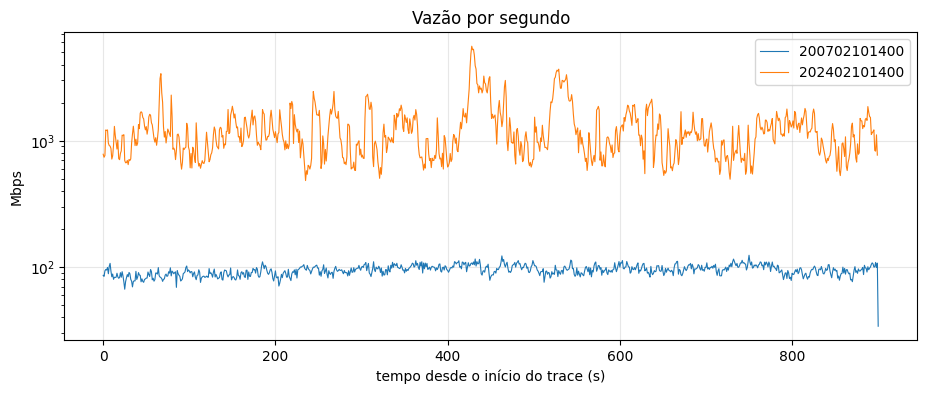

In [ ]:
# 4.3 Throughput por segundo dos dois traces (verificação visual)
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(11, 4))
for tid in TRACES:
    s = pd.read_parquet(os.path.join(PASTA_SAIDA, tid, f'{tid}_serie_1s.parquet'))
    ax.plot(s['t_s'], s['bytes'] * 8 / 1e6, lw=0.8, label=tid)
ax.set_xlabel('tempo desde o início do trace (s)'); ax.set_ylabel('Mbps'); ax.set_yscale('log')
ax.set_title('Throughput por segundo'); ax.legend(); ax.grid(alpha=0.3)
plt.show()

### 4.4 (Opcional) Conferência cruzada com o scapy
Decodifica o recorte com o scapy (referência lenta, porém confiável) e compara campo a campo com o parser vetorizado.

In [ ]:
VALIDAR_COM_SCAPY = True
N_VALIDAR = 3000

if VALIDAR_COM_SCAPY:
    import importlib, subprocess, sys
    if importlib.util.find_spec('scapy') is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'scapy'])
    from scapy.all import PcapReader, IP, IPv6, TCP, UDP
    for tid in TRACES:
        rec = os.path.join(PASTA_SAIDA, tid, f'{tid}_recorte.pcap')
        pk, _ = ler_pcap(rec)
        erros = 0
        with PcapReader(rec) as rd:
            for i, p in enumerate(rd):
                if i >= N_VALIDAR: break
                v = 4 if IP in p else (6 if IPv6 in p else 0)
                l4 = TCP if TCP in p else (UDP if UDP in p else None)
                frag = IP in p and p[IP].frag > 0
                esp = (p.wirelen if p.wirelen else len(p), v,
                       p[l4].sport if l4 and not frag else 0, p[l4].dport if l4 and not frag else 0)
                obt = (int(pk['tamanho'][i]), int(pk['versao'][i]), int(pk['sport'][i]), int(pk['dport'][i]))
                if esp != obt:
                    erros += 1
                    if erros <= 5: print('  diferença no pacote', i, 'scapy =', esp, 'nosso =', obt)
        print(f'{tid}: {min(i + 1, N_VALIDAR)} pacotes comparados, {erros} diferenças')

        12 MB lidos |    0.17 M pacotes |  0.24 M pkt/s (RAM do processo: 1.6 GB)   
  leitura concluída: 170,287 pacotes em 0.7 s
200702101400: 3000 pacotes comparados, 0 diferenças
        15 MB lidos |    0.21 M pacotes |  0.35 M pkt/s (RAM do processo: 1.6 GB)   
  leitura concluída: 213,220 pacotes em 0.6 s
202402101400: 3000 pacotes comparados, 0 diferenças


## 5. Dicionário de dados
Gera um `LEIAME_dados.md` na pasta de saída para acompanhar os arquivos que vão ser utilizados nas tarefas.

In [ ]:
DICIONARIO = '''# Dados pré-processados – MC833 Trabalho 3

Fonte: MAWI Working Group Traffic Archive, samplepoint-F (https://mawi.wide.ad.jp/mawi/).
Cada trace tem ~15 minutos, a partir das 14:00 no horário do Japão (JST = UTC+9).
Os endereços IP já vêm anonimizados pela MAWI e o payload dos pacotes foi removido na captura.

Convenções:
* `tamanho` = tamanho real do quadro no fio (wirelen), em bytes, incluindo o cabeçalho Ethernet.
* `tipo` ∈ {TCP, UDP, ICMP (inclui ICMPv6), Outro IP, Não IP}.
* `t_s` = segundos desde o primeiro pacote do trace; `timestamp` em UTC.

## <id>_serie_10ms.parquet  (todos os pacotes)
t_s, timestamp, bytes, pacotes, bytes_tcp, pacotes_tcp, bytes_udp, pacotes_udp, bytes_icmp, pacotes_icmp,
bytes_outro, pacotes_outro, bytes_ipv4, bytes_ipv6
-> Para outra resolução: df.groupby(df.t_s // 1).sum()  (1 s), df.groupby((df.t_s * 10) // 1).sum()  (100 ms) etc.

## <id>_serie_1s.parquet  (todos os pacotes)
t_s, timestamp, bytes, pacotes, ips_origem_unicos, ips_destino_unicos, fluxos_unicos, tcp_syn (SYN sem ACK)

## <id>_pacotes_amostra.parquet  (amostra aleatória uniforme; fração em resumo.json)
timestamp, t_s, tamanho, caplen (bytes efetivamente capturados), ip_len (campo de tamanho do IP),
versao_ip (4/6/0), protocolo (nº IANA), tipo, ip_origem, ip_destino, porta_origem, porta_destino, flags_tcp
(bits: FIN=1, SYN=2, RST=4, PSH=8, ACK=16, URG=32)

## <id>_fluxos.parquet  (os maiores fluxos em bytes; total de fluxos em resumo.json)
ip_origem, ip_destino, porta_origem, porta_destino, protocolo, tipo, versao_ip, pacotes, bytes, inicio_s, fim_s
Fluxo = 5-tupla unidirecional.

## <id>_hist_fluxos.parquet  (todos os fluxos)
limite_inferior (bins logarítmicos), fluxos_por_pacotes, fluxos_por_bytes

## <id>_portas.parquet  (todos os pacotes TCP/UDP)
tipo, porta_servico (= menor porta entre origem e destino), pacotes, bytes

## <id>_hist_tamanhos.parquet  (todos os pacotes)
versao_ip, tipo, tamanho, pacotes  -> histograma exato

## <id>_recorte.pcap
Primeiros segundos do pcap original (formato pcap clássico), para o exercício opcional de parsing.

## <id>_resumo.json
Metadados: início, duração, totais, throughput médio, distribuição por protocolo, nº de fluxos, fração amostrada.
'''
with open(os.path.join(PASTA_SAIDA, 'LEIAME_dados.md'), 'w', encoding='utf-8') as f:
    f.write(DICIONARIO)
print('LEIAME_dados.md gravado em', PASTA_SAIDA)

LEIAME_dados.md gravado em /content/drive/MyDrive/MC833A_T3_2026/dados
